# 01 · Análise Exploratória (EDA)
**Projeto Integrador BDED 2026.1: Sentinela Shadow AI**
Autor: Prof.º Esp. Hernane Bini

Este notebook explora os dados **já carregados no PostgreSQL** (esquema `dw`) pelo ETL.
Pré-requisito: `python run_pipeline.py` executado (ou o notebook `02_pipeline_completo.ipynb`).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from src import config

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 40)
engine = create_engine(config.pg_url())
def q(sql):
    with engine.connect() as c:
        return pd.read_sql(sql, c)
print("Conectado a", config.PG_DB, "em", config.PG_HOST)

Conectado a sentinela_dw em localhost


## 1. Visão geral do modelo estrela

In [2]:
q('''SELECT 'dim_data' tabela, COUNT(*) linhas FROM dw.dim_data UNION ALL
SELECT 'dim_usuario', COUNT(*) FROM dw.dim_usuario UNION ALL
SELECT 'dim_estacao', COUNT(*) FROM dw.dim_estacao UNION ALL
SELECT 'dim_servico', COUNT(*) FROM dw.dim_servico UNION ALL
SELECT 'fato_evento_acesso', COUNT(*) FROM dw.fato_evento_acesso UNION ALL
SELECT 'quarentena_eventos', COUNT(*) FROM dw.quarentena_eventos''')

,tabela,linhas
0,dim_data,149
1,dim_usuario,650
2,dim_estacao,120
3,dim_servico,42
4,fato_evento_acesso,49679
5,quarentena_eventos,40


In [3]:
qualidade = json.loads((config.REPORTS / "qualidade_dados.json").read_text(encoding="utf-8"))
pd.Series({k: v for k, v in qualidade.items() if not isinstance(v, dict)}, name="valor").to_frame()

,valor
usuarios_brutos,658
usuarios_duplicados_removidos,8
categorias_padronizadas,3
servicos_no_catalogo_externo,42
tamanho_catalogo_externo,60
eventos_brutos,51210
eventos_duplicados_removidos,1491
dominios_normalizados,2436
exposicao_nula_imputada,488
eventos_quarentena,40


## 2. Ações do Sentinela (allow / warn / block)

In [4]:
acoes = q("SELECT acao, COUNT(*) eventos FROM dw.fato_evento_acesso GROUP BY acao ORDER BY eventos DESC")
acoes["pct"] = (100 * acoes.eventos / acoes.eventos.sum()).round(1)
acoes

,acao,eventos,pct
0,warn,41045,82.6
1,block,4404,8.9
2,allow,4230,8.5


## 3. Série diária e efeito do calendário acadêmico (fontes 2 e 4)

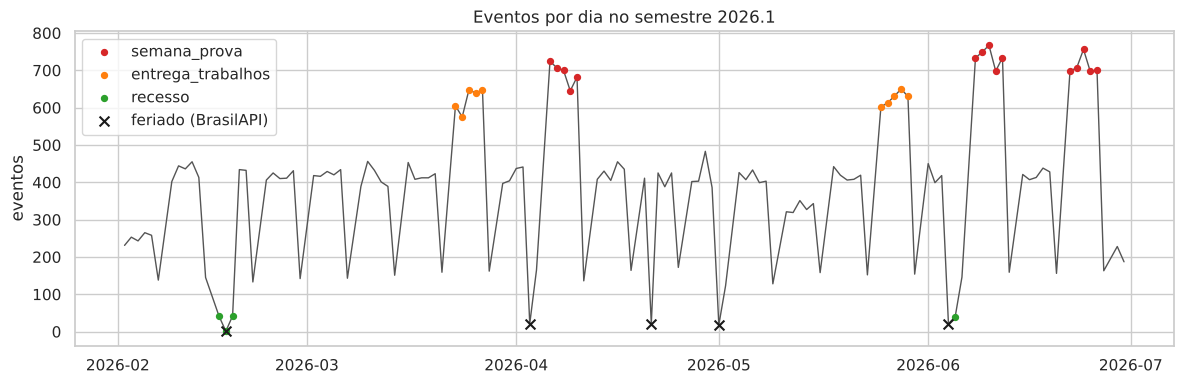

In [5]:
painel = q("SELECT * FROM dw.vw_painel_diario ORDER BY data")
painel["data"] = pd.to_datetime(painel["data"])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(painel.data, painel.eventos, lw=1, color="#555")
for tipo, cor in {"semana_prova": "#d62728", "entrega_trabalhos": "#ff7f0e", "recesso": "#2ca02c"}.items():
    m = painel.tipo_periodo == tipo
    ax.scatter(painel.data[m], painel.eventos[m], color=cor, s=18, label=tipo, zorder=3)
fer = painel[painel.feriado]
ax.scatter(fer.data, fer.eventos, marker="x", color="k", s=50, label="feriado (BrasilAPI)", zorder=4)
ax.set_title("Eventos por dia no semestre 2026.1"); ax.set_ylabel("eventos"); ax.legend()
plt.tight_layout(); plt.savefig(config.FIGS / "eda_serie_diaria.png", dpi=130); plt.show()

In [6]:
q('''SELECT d.tipo_periodo, COUNT(DISTINCT d.data) dias, COUNT(*) eventos,
       ROUND(COUNT(*)::numeric/COUNT(DISTINCT d.data),1) eventos_por_dia,
       ROUND(AVG(f.prosseguiu::int)::numeric,3) taxa_ignorou_alerta
FROM dw.fato_evento_acesso f JOIN dw.dim_data d USING (data_id)
GROUP BY 1 ORDER BY eventos_por_dia DESC''')

,tipo_periodo,dias,eventos,eventos_por_dia,taxa_ignorou_alerta
0,semana_prova,15,10697,713.1,0.569
1,entrega_trabalhos,10,6240,624.0,0.538
2,aulas,87,29292,336.7,0.434
3,evento_academico,5,1661,332.2,0.433
4,inicio_aulas,5,1250,250.0,0.435
5,encerramento,2,415,207.5,0.430
6,recesso,4,124,31.0,0.481


## 4. Base de modelagem: alertas (`dw.vw_base_alertas`)

In [7]:
base = q("SELECT * FROM dw.vw_base_alertas")
print(base.shape)
print("Taxa de alertas ignorados (classe positiva):", round(base.alvo_prosseguiu.mean(), 3))
base.head()

(41045, 30)
Taxa de alertas ignorados (classe positiva): 0.476


,evento_id,ts_local,data,hora,dia_semana,tipo_periodo,semana_prova,entrega_trabalhos,feriado,semana_letiva,perfil,curso,area_ti,semestre,turno,treinado_ia,local,dominio,categoria,catalogado_interno,no_catalogo_externo,exposicao,navegador,alertas_previos_dia,n_alertas_hist,n_ignorados_hist,n_bloqueios_hist,n_eventos_hist,tempo_decisao_ms,alvo_prosseguiu
0,637a9e06-f0f6-ecad-6f34-e4cce5df0bc6,2026-02-02 13:16:33,2026-02-02,13,0,inicio_aulas,False,False,False,1,aluno,Enfermagem,False,7.0,manha,False,laboratorio,claude.ai,chat_llm,True,True,contexto_baixo,chrome,0,0,0,0,0,4148,0
1,36f12f5f-18d5-40ec-0074-39f57ae6653a,2026-02-06 08:02:13,2026-02-06,8,4,inicio_aulas,False,False,False,1,aluno,Enfermagem,False,7.0,manha,False,laboratorio,suno.com,audio,True,True,nenhuma,chrome,0,1,0,0,1,10761,0
2,1382e38e-d421-c598-2c5c-6cf9273fd739,2026-02-06 11:52:39,2026-02-06,11,4,inicio_aulas,False,False,False,1,aluno,Enfermagem,False,7.0,manha,False,laboratorio,rytr.me,escrita_parafrase,True,True,contexto_baixo,chrome,1,2,0,0,2,1612,1
3,702140ba-6267-f9ec-4508-5fe98ab16828,2026-02-09 08:35:55,2026-02-09,8,0,aulas,False,False,False,2,aluno,Enfermagem,False,7.0,manha,False,laboratorio,photomath.com,resolucao_exercicios,True,True,nenhuma,chrome,0,3,1,0,3,8377,0
4,50fa4666-4655-a1f8-5973-e740e83451e9,2026-02-19 17:28:50,2026-02-19,17,3,aulas,False,False,False,3,aluno,Enfermagem,False,7.0,manha,False,laboratorio,claude.ai,chat_llm,True,True,contexto_alto,chrome,0,4,1,0,4,1095,0


In [8]:
base.isna().sum()[lambda s: s > 0]

curso       3582
semestre    7928
dtype: int64

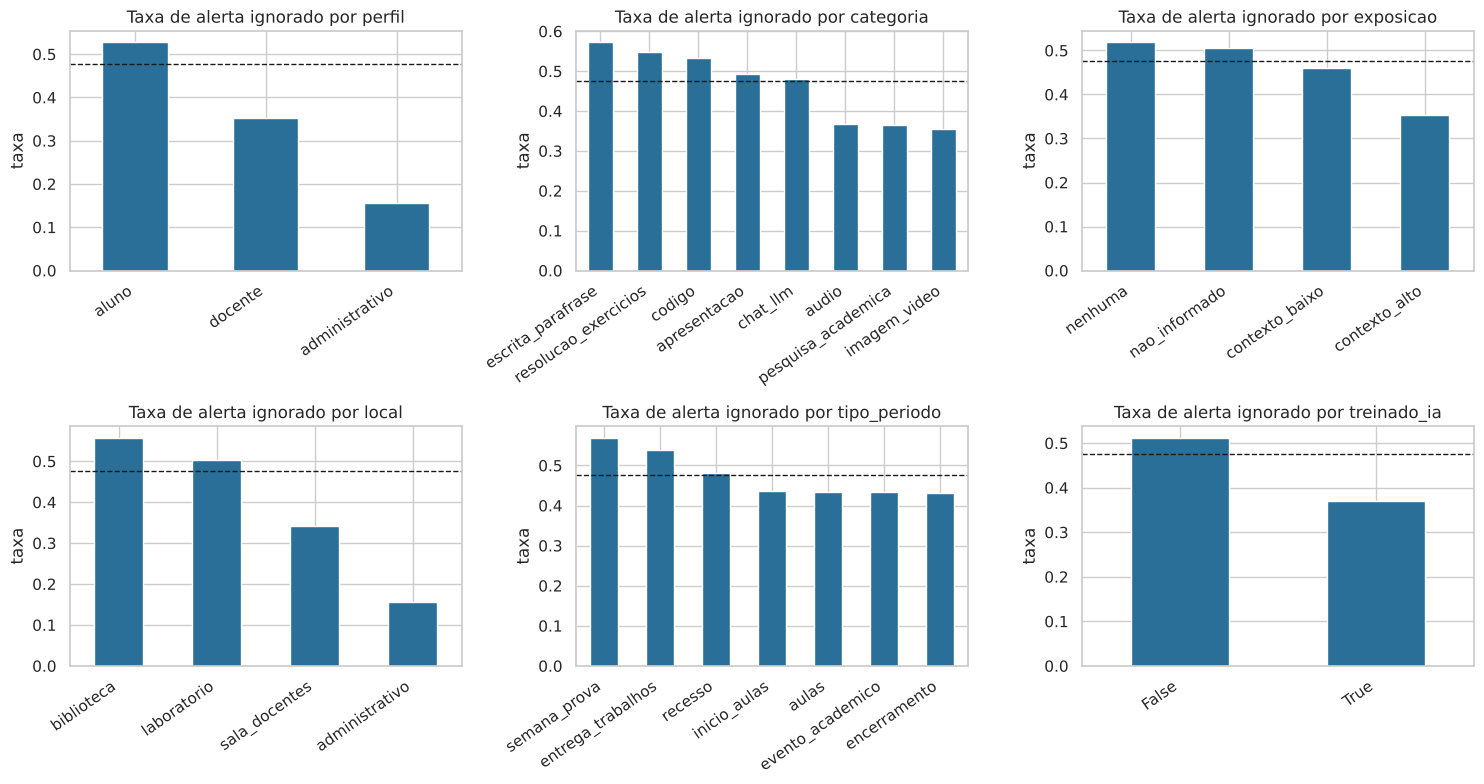

In [9]:
def taxa(col, ax, ordem=None):
    t = base.groupby(col)["alvo_prosseguiu"].mean().sort_values(ascending=False)
    if ordem is not None: t = t.reindex(ordem)
    t.plot.bar(ax=ax, color="#2a6f97"); ax.axhline(base.alvo_prosseguiu.mean(), ls="--", c="k", lw=1)
    ax.set_title(f"Taxa de alerta ignorado por {col}"); ax.set_ylabel("taxa"); ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for col, ax in zip(["perfil", "categoria", "exposicao", "local", "tipo_periodo", "treinado_ia"], axs.ravel()):
    taxa(col, ax)
plt.tight_layout(); plt.savefig(config.FIGS / "eda_taxas_categoricas.png", dpi=130); plt.show()

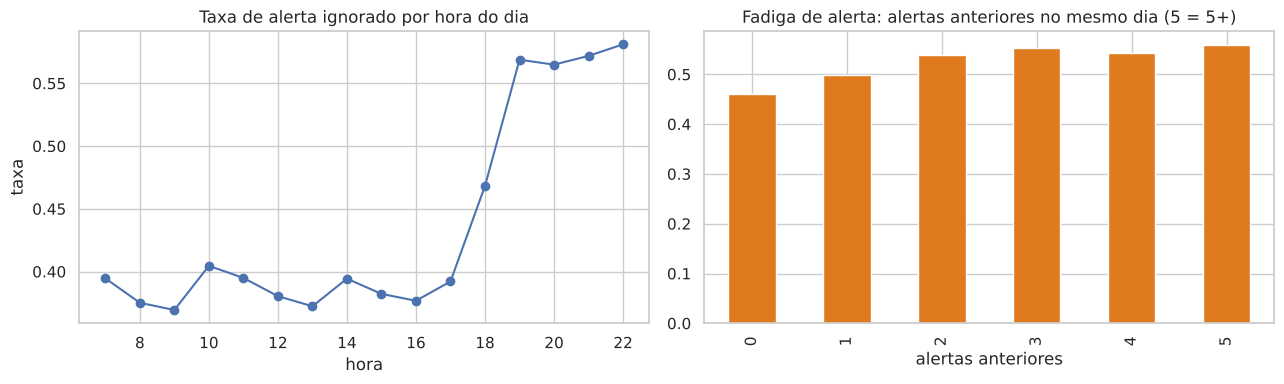

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
base.groupby("hora")["alvo_prosseguiu"].mean().plot(ax=axs[0], marker="o")
axs[0].set_title("Taxa de alerta ignorado por hora do dia"); axs[0].set_ylabel("taxa")
base.assign(alertas=base.alertas_previos_dia.clip(upper=5)).groupby("alertas")["alvo_prosseguiu"].mean().plot.bar(ax=axs[1], color="#e07a1f")
axs[1].set_title("Fadiga de alerta: alertas anteriores no mesmo dia (5 = 5+)"); axs[1].set_xlabel("alertas anteriores")
plt.tight_layout(); plt.savefig(config.FIGS / "eda_hora_fadiga.png", dpi=130); plt.show()

## 5. Shadow AI descoberta (fonte 3: catálogo público do GitHub)

In [11]:
rk = q("SELECT * FROM dw.vw_ranking_servicos ORDER BY acessos DESC")
print("Serviços fora do catálogo interno (descobertos):", (~rk.catalogado_interno).sum())
rk.head(15)

Serviços fora do catálogo interno (descobertos): 12


,servico,dominio,categoria,politica,catalogado_interno,acessos,usuarios,taxa_ignorou_alerta
0,ChatGPT,chatgpt.com,chat_llm,warn,True,5584,627,0.488
1,Character.AI,character.ai,chat_llm,block,True,2194,545,NaN
2,Meta AI,meta.ai,chat_llm,warn,True,2167,563,0.513
3,Copilot (licenca institucional),copilot.microsoft.com,chat_llm,allow,True,2165,561,NaN
4,kimi.com,kimi.com,chat_llm,warn,False,2147,561,0.429
5,chat.qwen.ai,chat.qwen.ai,chat_llm,warn,False,2128,556,0.447
6,ChatGPT (legado),chat.openai.com,chat_llm,warn,True,2122,567,0.495
7,grok.com,grok.com,chat_llm,warn,False,2108,559,0.451
8,Gemini (Workspace edu),gemini.google.com,chat_llm,allow,True,2065,557,NaN
9,Claude,claude.ai,chat_llm,warn,True,2050,566,0.483


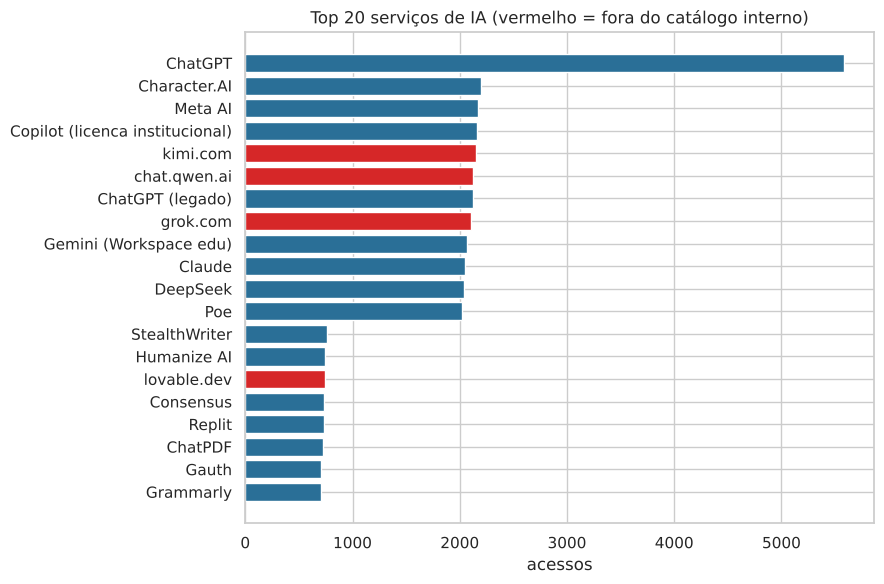

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))
top = rk.head(20).iloc[::-1]
ax.barh(top.servico, top.acessos, color=np.where(top.catalogado_interno, "#2a6f97", "#d62728"))
ax.set_title("Top 20 serviços de IA (vermelho = fora do catálogo interno)"); ax.set_xlabel("acessos")
plt.tight_layout(); plt.savefig(config.FIGS / "eda_top_servicos.png", dpi=130); plt.show()

## 6. Histórico do usuário e correlações

              size   mean
faixa_hist               
(0.0, 0.2]    5069  0.164
(0.2, 0.35]   7457  0.319
(0.35, 0.5]  11328  0.450
(0.5, 0.65]   8470  0.584
(0.65, 0.8]   7119  0.704
(0.8, 1.0]    1602  0.806


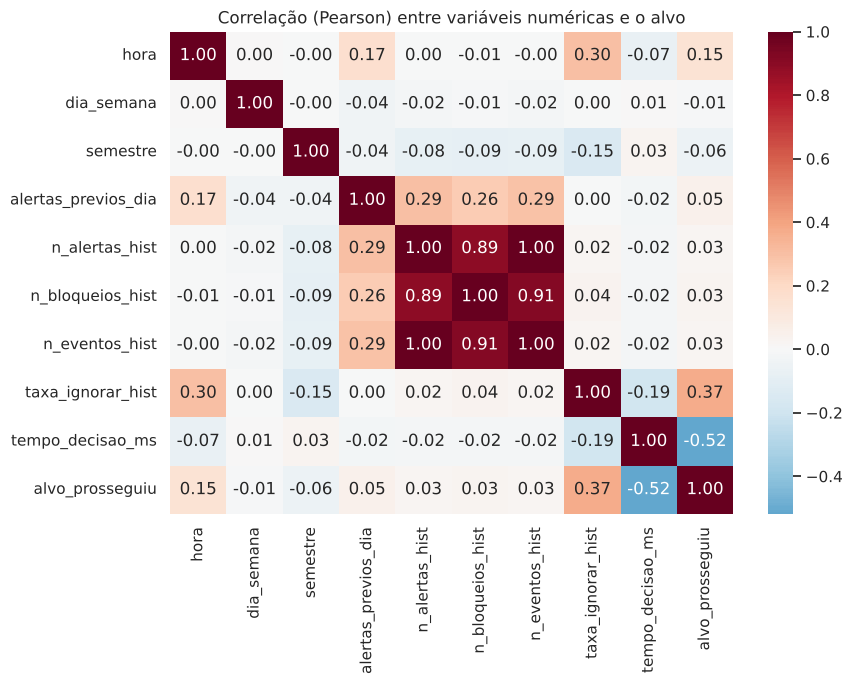

In [13]:
b = base.copy()
b["taxa_ignorar_hist"] = (b.n_ignorados_hist + 1) / (b.n_alertas_hist + 2)
b["faixa_hist"] = pd.cut(b.taxa_ignorar_hist, [0, .2, .35, .5, .65, .8, 1])
print(b.groupby("faixa_hist", observed=True)["alvo_prosseguiu"].agg(["size", "mean"]).round(3))
num = ["hora", "dia_semana", "semestre", "alertas_previos_dia", "n_alertas_hist", "n_bloqueios_hist",
       "n_eventos_hist", "taxa_ignorar_hist", "tempo_decisao_ms", "alvo_prosseguiu"]
plt.figure(figsize=(9, 7))
sns.heatmap(b[num].corr(numeric_only=True), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlação (Pearson) entre variáveis numéricas e o alvo")
plt.tight_layout(); plt.savefig(config.FIGS / "eda_correlacao.png", dpi=130); plt.show()

## 7. Achados da EDA
1. **Calendário importa:** semanas de prova e de entrega de trabalhos concentram mais eventos por dia e maior taxa de alerta ignorado; feriados (BrasilAPI) quase zeram o uso.
2. **Perfil e letramento:** alunos ignoram mais alertas que docentes e administrativos; quem passou pelo treinamento de IA ignora menos, em todos os perfis.
3. **Categoria do serviço:** paráfrase/escrita e resolução de exercícios têm as maiores taxas, ligadas a risco de integridade acadêmica.
4. **Exposição de contexto alta** (ex.: página com campo de upload) reduz a chance de prosseguir: o alerta funciona melhor quando o risco é visível.
5. **Fadiga de alerta:** quanto mais alertas no mesmo dia, maior a taxa de ignorar.
6. **Histórico do usuário** (taxa de alertas ignorados anteriormente) é o sinal mais forte.
7. **Atenção a vazamento:** `tempo_decisao_ms` correlaciona com o alvo, mas só existe **depois** da decisão; não pode ser usada como feature.